# When does a waiting line become persistent?

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 11 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/11_Factory_Queues_Discrete_Event_Simulation.ipynb)

**Factory and service queues: an event-driven Python case study**  
**Audience:** first-year students from any engineering major. Run the cells from top to bottom with Python, NumPy, and Matplotlib.

Imagine a campus lab with one technician who checks students' equipment requests. A student arrives with a request, the technician works on one request at a time, and others wait. On a busy afternoon the line grows. Is this a passing rush that will clear, or are requests arriving too quickly for one technician to keep up? Would a larger waiting area help, or would faster service make a more lasting difference?

That small story is also a model of parts awaiting inspection, support tickets awaiting an engineer, or tasks awaiting one computer. In this notebook, a **job** simply means one request for service; it does not mean a person's employment. We use an intentionally simple one-server model so that the logic of *arrival → possible wait → service → departure* is visible. You need no prior knowledge of factory operations or service management. The one-minute service times in early examples are teaching numbers, not measured times at a real lab.

**Your challenge:** use Python to make a claim about waiting that you can defend with evidence. First predict the fate of four requests by hand. Then build a calendar of arrival and departure **events**, represent requests and events with classes, and compare a readable sorted list with a faster priority queue (heap). Finally, inspect plots and counts to decide whether the backlog is growing and what a capacity limit changes. Each executable code line has an adjacent explanatory comment; pause at the questions before running the next cell.

**What you will check:** attempted arrivals = accepted arrivals + rejected arrivals; accepted arrivals = completed departures + jobs still in the system at any instant; and a capacity limit $K$ is never exceeded. A job being served counts toward $K$. We use reproducible synthetic schedules, not factory measurements. Figures have consistent units and captions and are stored as scalable SVG with a high-resolution PNG fallback. To export a figure as PDF after running its cell, insert `fig.savefig("queue_figure.pdf", bbox_inches="tight")` before `plt.show()`.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 4, Objects |
| **Time** | about 60 min (about 120 min with exercises) |
| **Before this** | Notebook 10 (classes); functions, lists and dictionaries. |
| **Essential** | Sections 1–5, 7 and 9. |
| **Optional on a first reading** | Sections 6 and 8 (queue limits; capacity versus buffer size). |
| **Next** | 12, Monte Carlo sampling and integration. |

**You have understood this notebook if you can, without looking back:**

1. Compare the arrival rate with the service rate, and predict whether a queue will keep growing.
2. Explain how an event list kept in a heap drives a discrete-event simulation.
3. Repeat a random experiment with several seeds and report a range, not one number.
4. Check job conservation: arrivals = departures + jobs still in the system.
5. Use simulation results to argue for a finite waiting area of a given size.

**Not expected of you:** Queueing-theory formulas beyond ρ = λ/μ.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## 1. From a familiar line to a model

We will follow the **campus lab help desk** as a running example. A real desk can have breaks, priorities, and several technicians; for now, we deliberately keep **one technician** and a first-come-first-served rule. This lets us check every event by hand before trusting a longer simulation.

| Model word | Meaning at the lab desk | Python representation or measurement |
|:--|:--|:--|
| Job | One student's equipment request | A `Job` with an identifier, arrival time, and service duration |
| Arrival | A request reaches the desk | An arrival time and later an arrival `Event` |
| Server | The technician handling one request | One active job at most |
| Service duration | Time spent handling a request | A positive number of minutes |
| Waiting line | Requests accepted but not yet started | A first-come-first-served `deque` |
| Departure | A request is completed and leaves | A departure `Event` |
| Capacity $K$ | Maximum requests admitted at once | Active request **plus** those waiting |

If the technician is free at arrival, service starts immediately. Otherwise the accepted request waits. Its **waiting time** is service-start time minus arrival time. Its **time in the system** is departure time minus arrival time, including both waiting and service. In this notebook, *queue length* counts **waiting jobs only**; *number in the system* counts waiting jobs **plus** the one in service. Thus $K=8$ admits at most eight requests at once, with at most seven waiting while one is served. `capacity=None` means unlimited space; if the limited system is full, the new request is recorded as rejected.

At exactly the same timestamp, we process a **departure before an arrival**. This frees a place for a simultaneous incoming request. There is no universal tie rule for every real desk: the rule is a choice in our model, and the code tests its consequences.

In [1]:
# Import NumPy for arrays, random input schedules, and numerical summaries.
import numpy as np
# Import Matplotlib for time traces and diagnostic figures.
import matplotlib.pyplot as plt
# Import a deque for efficient removal from the front of the waiting line.
from collections import deque
# Import dataclass tools to define compact objects with named fields.
from dataclasses import dataclass, field
# Import heap operations for the later efficient event calendar.
import heapq
# Import a high-resolution clock for a small illustrative speed comparison.
import time as clock
# Select a consistent readable font across all figures.
plt.rcParams["font.family"] = "DejaVu Sans"
# Use compact normal text that remains legible in a report.
plt.rcParams["font.size"] = 10
# Make axis names slightly more prominent than tick values.
plt.rcParams["axes.labelsize"] = 10
# Keep figure titles modest so data remain the focus.
plt.rcParams["axes.titlesize"] = 11
# Use uniform readable tick and legend sizes.
plt.rcParams["xtick.labelsize"] = 9
# Give vertical tick values the same size as horizontal ones.
plt.rcParams["ytick.labelsize"] = 9
# Keep legend entries compact.
plt.rcParams["legend.fontsize"] = 9
# Hide the unused top border on ordinary plots.
plt.rcParams["axes.spines.top"] = False
# Hide the unused right border; separate quantities get separate axes.
plt.rcParams["axes.spines.right"] = False
# Provide a crisp notebook display where inline graphics use PNG.
plt.rcParams["figure.dpi"] = 160
# Preserve editable text when a vector SVG is exported.
plt.rcParams["svg.fonttype"] = "none"
# Use a consistent set of strong colors with line-style differences as a second cue.
colors = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00", "purple": "#CC79A7", "gray": "#4D4D4D"}

Four jobs arrive at 0.0, 0.4, 1.0, and 1.4 minutes. Each takes exactly 1.0 minute of service. With no capacity limit, the first starts at 0.0 and finishes at 1.0; the second waits and then runs from 1.0 to 2.0. The following loop applies the same rule to all four jobs. **Before running it, predict when job 3 (the fourth request) starts and how long that student waits.** This direct calculation will give us a result against which to check the event simulator.

In [2]:
# Store the four known arrival instants in chronological order.
toy_arrivals = np.array([0.0, 0.4, 1.0, 1.4])
# Give each job one minute of service for easily checked arithmetic.
toy_services = np.ones(4)
# Allocate a list for each job's actual service-start time.
toy_starts = []
# Allocate a list for each job's completion or departure time.
toy_finishes = []
# Start with the server available at time zero.
previous_finish = 0.0
# Work through the four jobs in arrival order.
for arrival, service in zip(toy_arrivals, toy_services):
    # Start the job when both the job and the single server are available.
    start = max(arrival, previous_finish)
    # Add the job's own service duration to find its finish time.
    finish = start + service
    # Record the two times for this job.
    toy_starts.append(start)
    # Record departure so the next job cannot start too early.
    toy_finishes.append(finish)
    # Update the time when the server is next free.
    previous_finish = finish
# Calculate waiting as service start minus arrival for each job.
toy_waits = np.array(toy_starts) - toy_arrivals
# Display a compact numerical schedule for independent hand checking.
for job_id in range(len(toy_arrivals)):
    # Print arrival, service start, departure, and waiting time in minutes.
    print(f"Job {job_id}: arrive {toy_arrivals[job_id]:.1f}, start {toy_starts[job_id]:.1f}, depart {toy_finishes[job_id]:.1f}, wait {toy_waits[job_id]:.1f} min")
# Check the first job starts immediately and the fourth waits 1.6 minutes.
assert np.allclose(toy_waits, [0.0, 0.6, 1.0, 1.6])

Job 0: arrive 0.0, start 0.0, depart 1.0, wait 0.0 min
Job 1: arrive 0.4, start 1.0, depart 2.0, wait 0.6 min
Job 2: arrive 1.0, start 2.0, depart 3.0, wait 1.0 min
Job 3: arrive 1.4, start 3.0, depart 4.0, wait 1.6 min


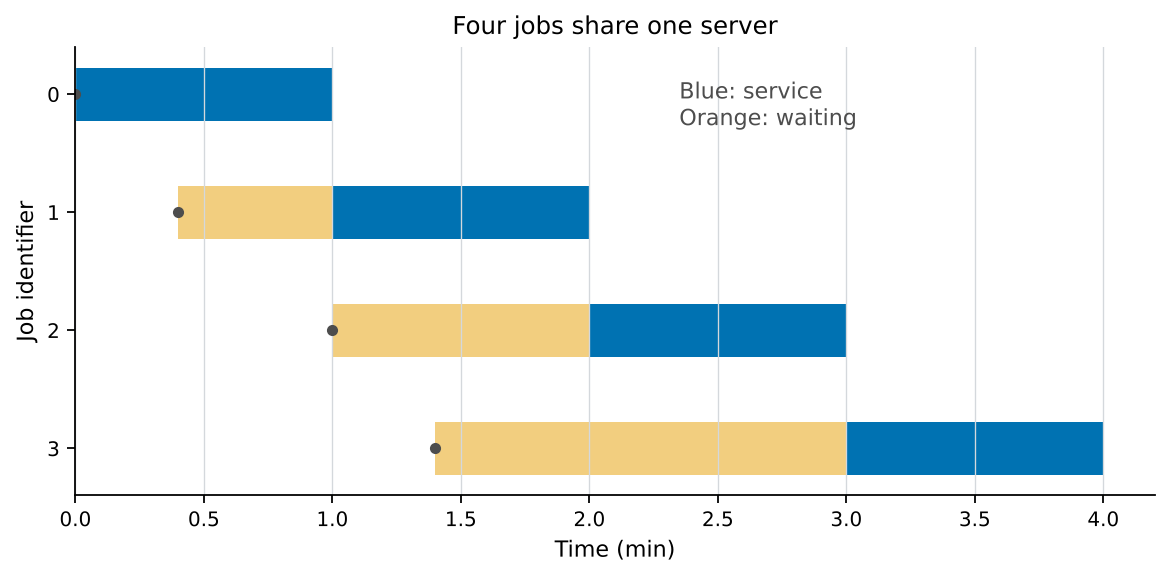

In [3]:
# Create a horizontal timeline for the four sequential service intervals.
fig, ax = plt.subplots(figsize=(7.2, 3.5), layout="constrained")
# Draw one row per job, with a faint waiting segment and a solid service segment.
for job_id in range(len(toy_arrivals)):
    # Draw the time between arrival and service start as a pale waiting bar.
    ax.barh(job_id, toy_waits[job_id], left=toy_arrivals[job_id], height=0.45, color=colors["orange"], alpha=0.50)
    # Draw the one-minute occupied-server interval as a blue service bar.
    ax.barh(job_id, toy_services[job_id], left=toy_starts[job_id], height=0.45, color=colors["blue"])
    # Mark the actual arrival time with a small dark point.
    ax.plot(toy_arrivals[job_id], job_id, "o", color=colors["gray"], markersize=4)
# Identify physical time and its minute unit.
ax.set_xlabel("Time (min)")
# Give the vertical axis the job identifiers displayed in the table.
ax.set_ylabel("Job identifier")
# Mark each of the four numbered job rows explicitly.
ax.set_yticks(range(4))
# Put job zero at the top so rows read in arrival order.
ax.invert_yaxis()
# State the lesson illustrated by the timing bars.
ax.set_title("Four jobs share one server")
# Add a small direct key for the two colored time intervals.
ax.text(2.35, 0.1, "Blue: service\nOrange: waiting", color=colors["gray"], va="center")
# Keep the complete four-minute service schedule in view.
ax.set_xlim(0.0, 4.2)
# Add subtle vertical reference guides for comparing times.
ax.grid(axis="x", color="#D4D8DC", linewidth=0.6)
# Render the hand-checkable schedule.
plt.show()

**Figure 1.** Arrival dots, orange waiting intervals, and blue service intervals for the four-job unlimited-queue example. Only one blue interval occupies the server at a time.

## 2. A first clue: compare input and processing rates

Suppose our technician can finish about one request per minute while continuously busy. If requests keep arriving every 0.8 minute, they come in at 1.25 requests per minute. More work enters than one technician can finish. An extra waiting chair might hold one more student, but it cannot increase the technician's completion rate. If arrivals stop, even a long line can eventually clear: **persistent** here asks what would happen if the same input pattern continued.

Let $\lambda$ be the *average number arriving per minute* and $\mu$ the *average number the server could complete per minute while continuously busy*. The ratio $\rho=\lambda/\mu$ is the **offered load**. For jobs every 1.25 min and service lasting 1.0 min, $\lambda=0.8$ and $\mu=1.0$ jobs/min, so $\rho=0.8$. For jobs every 0.8 min, $\lambda=1.25$ and $\rho=1.25$. **Predict:** Which regular schedule should produce growing waits before you inspect Figure 2?

With an **unlimited** line and persistent arrival rate above service capacity ($\rho>1$), unfinished work must accumulate over a long enough time. With random arrivals and services, the special $M/M/1$ model has a steady-state distribution only when $\rho<1$; being below one does **not** promise an empty line at every instant. At $\rho=1$ there is no stationary finite-mean queue in that idealized model. A finite run can have a long queue by chance even when $\rho<1$, so we will distinguish a model's long-run condition from one observed time trace.

In [4]:
# Set a common one-minute deterministic service time.
unit_service = 1.0
# Choose a slower-arrival gap and a faster-arrival gap in minutes.
arrival_gaps = [1.25, 0.80]
# Convert each gap to jobs arriving per minute, assuming regular arrivals.
arrival_rates = [1.0 / gap for gap in arrival_gaps]
# Convert the service duration to the server's jobs-per-minute capacity.
service_rate = 1.0 / unit_service
# Calculate offered loads for the two regular-arrival cases.
loads = [rate / service_rate for rate in arrival_rates]
# Print the rate ratios with units and descriptive labels.
for gap, rate, load in zip(arrival_gaps, arrival_rates, loads):
    # Translate each schedule from a time gap to an arrival-rate comparison.
    print(f"Gap={gap:.2f} min; λ={rate:.2f} jobs/min; μ={service_rate:.2f} jobs/min; ρ={load:.2f}")
# Verify the cases lie on different sides of the offered-load threshold.
assert loads[0] < 1.0 < loads[1]

Gap=1.25 min; λ=0.80 jobs/min; μ=1.00 jobs/min; ρ=0.80
Gap=0.80 min; λ=1.25 jobs/min; μ=1.00 jobs/min; ρ=1.25


In [5]:
# Make 200 regularly spaced arrival times for the less-loaded case.
slow_arrivals = np.arange(200) * arrival_gaps[0]
# Make 200 faster arrival times for the overloaded case.
fast_arrivals = np.arange(200) * arrival_gaps[1]
# Create a helper for waiting times using the hand-calculation recurrence.
def sequential_waits(arrivals, service_durations):
    # Start with an empty collection of waiting times.
    waits = []
    # Begin when the server is free at time zero.
    free_at = 0.0
    # Visit jobs in their nondecreasing arrival order.
    for arrival, duration in zip(arrivals, service_durations):
        # Determine when the job and server are both ready.
        start = max(arrival, free_at)
        # Store how long the job waited before service.
        waits.append(start - arrival)
        # Move the server's next-free time beyond this job's service.
        free_at = start + duration
    # Return a NumPy array for later numerical comparisons.
    return np.array(waits)
# Apply the recurrence to 200 jobs with relatively slow arrivals.
slow_waits = sequential_waits(slow_arrivals, np.ones(200))
# Apply the same service rule to 200 jobs arriving faster than capacity.
fast_waits = sequential_waits(fast_arrivals, np.ones(200))
# Show how long the final job in each schedule waits.
print(f"Wait of job 199: ρ=0.8 gives {slow_waits[-1]:.1f} min; ρ=1.25 gives {fast_waits[-1]:.1f} min")
# Check that regular slow arrivals never require waiting in this constructed case.
assert np.allclose(slow_waits, 0.0)

Wait of job 199: ρ=0.8 gives 0.0 min; ρ=1.25 gives 39.8 min


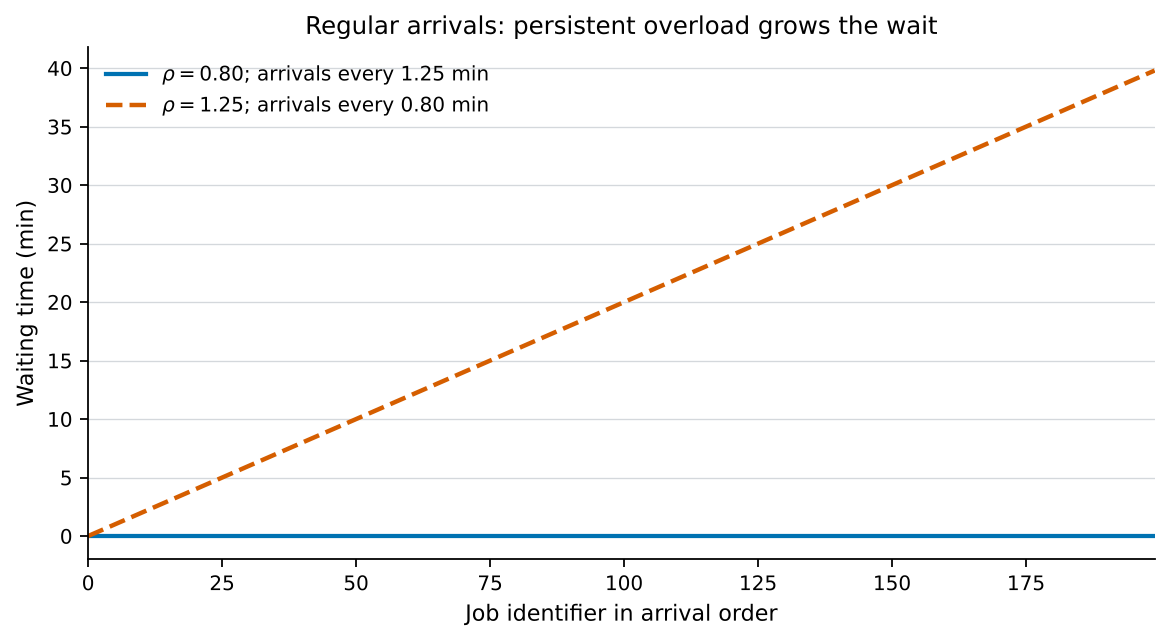

In [6]:
# Create a figure comparing deterministic waiting time across job indices.
fig, ax = plt.subplots(figsize=(7.2, 3.9), layout="constrained")
# Draw the zero-wait case with markers spaced far enough apart to remain legible.
ax.plot(np.arange(200), slow_waits, color=colors["blue"], linewidth=1.9, label=r"$\rho=0.80$; arrivals every 1.25 min")
# Draw the increasing-wait case with a contrasting dashed line.
ax.plot(np.arange(200), fast_waits, color=colors["red"], linestyle="--", linewidth=2.0, label=r"$\rho=1.25$; arrivals every 0.80 min")
# Name the job sequence on the horizontal axis.
ax.set_xlabel("Job identifier in arrival order")
# Label the time spent waiting and its minute unit.
ax.set_ylabel("Waiting time (min)")
# Explain why the two lines differ in this controlled schedule.
ax.set_title("Regular arrivals: persistent overload grows the wait")
# Keep all 200 job indices visible.
ax.set_xlim(0, 199)
# Identify the two offered loads directly in the legend.
ax.legend(loc="upper left", frameon=False)
# Add light horizontal guides for reading time differences.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render the deterministic threshold comparison.
plt.show()

**Figure 2.** With a one-minute service time, regular arrivals spaced 1.25 min apart produce no waiting. Arrivals spaced 0.80 min apart add roughly 0.20 min of waiting to each successive job. This controlled deterministic example isolates the capacity mismatch; random schedules behave less smoothly.

## 3. Turn the schedule into an event list

Imagine writing just two kinds of entry in the desk's logbook: **“request arrived”** and **“request completed.”** The line changes only at these instants. A simulation can therefore jump from event to event instead of checking the desk every millisecond. The event list is a calendar of what the program must handle next, rather than a list of students waiting for the technician.

An `Event` object stores its time, tie priority, insertion sequence, kind, and job ID. The `@dataclass` decorator creates a short class from these named fields; `order=True` lets Python compare events in field order. We exclude the descriptive fields from ordering so that **time, departure-first priority, then sequence** determine which event is processed next. **Predict:** If a departure and an arrival both occur at minute 1.0 in a full two-place system, why does their order matter?

In [7]:
# Ask dataclass to provide a constructor and comparisons based on selected fields.
@dataclass(order=True)
# Define an event type rather than using unexplained tuple positions.
class Event:
    # Store physical event time as the first sorting key.
    time: float
    # Use zero for departures and one for arrivals at the same time.
    priority: int
    # Keep a predictable order for events that share time and priority.
    sequence: int
    # Store a readable description without using it to sort events.
    kind: str = field(compare=False)
    # Identify the affected job without using the ID as a sorting rule.
    job_id: int = field(compare=False)

In [8]:
# Give each accepted job an identity, arrival time, duration, and eventual start.
@dataclass
# Define job information as named fields to avoid ambiguous array indices.
class Job:
    # Store the zero-based identifier from the input arrival schedule.
    identifier: int
    # Store the physical time this job attempted to enter the system.
    arrived_at: float
    # Store the positive time required by this job's service.
    service_time: float
    # Leave the start time unknown until the server actually begins the job.
    started_at: float | None = None

In [9]:
# Create a same-time arrival event with a lower tie priority.
arrival_event = Event(1.0, 1, 0, "arrival", 2)
# Create a same-time departure event with the preferred priority zero.
departure_event = Event(1.0, 0, 1, "departure", 0)
# Put arrival first deliberately to demonstrate that sorting fixes the order.
unsorted_events = [arrival_event, departure_event]
# Sort the list according to time, tie priority, and insertion sequence.
sorted_events = sorted(unsorted_events)
# Print the resulting kinds so the departure-first policy is visible.
print("At t=1.0, process:", [event.kind for event in sorted_events])
# Check that a same-time departure frees capacity before an arrival is considered.
assert [event.kind for event in sorted_events] == ["departure", "arrival"]

At t=1.0, process: ['departure', 'arrival']


### Two ways to maintain the event calendar

The **sorted-list** version appends each new event, sorts all pending events, and removes the earliest one. Its steps are easy to inspect. The **heap** version uses Python's `heapq` priority queue, where insertion and removal scale much better as the calendar grows. Both use the *same Event objects and tie rule*. We will check that they produce identical physical results before comparing their execution times.

In [10]:
# Define one insertion operation that can use either calendar representation.
def push_event(calendar, event, method):
    # Test whether the efficient heap representation was requested.
    if method == "heap":
        # Insert the event while keeping the heap's minimum readily available.
        heapq.heappush(calendar, event)
    # Handle the deliberately simple unsorted-list representation.
    else:
        # Append now and postpone sorting until the next removal.
        calendar.append(event)
# Define one removal operation that always returns the earliest event.
def pop_event(calendar, method):
    # Use the heap's logarithmic-time removal when appropriate.
    if method == "heap":
        # Take the smallest event according to Event's ordering fields.
        return heapq.heappop(calendar)
    # Sort all pending events to make the teaching implementation explicit.
    calendar.sort()
    # Remove the earliest sorted event from the list's front.
    return calendar.pop(0)

### The single-server simulation

The function below holds a waiting `deque`, one active job or `None`, and a calendar of future events. It initially schedules every arrival. An accepted arrival either starts service immediately or joins the waiting line. A departure frees the server, records a completed job, and starts the next waiting job. The function continues **after the final arrival until all accepted jobs have departed**. Therefore its final completed count equals its accepted count; a separate snapshot records how many jobs were still in the system just after the last arrival.

At every event we record both the waiting count and the total in the system. We also assert the conservation identities during the run, so an implementation error fails close to where it occurs. If `capacity` is set, it includes the active job.

In [11]:
# Define an event-driven, one-server, first-come-first-served queue simulator.
def simulate_queue(arrival_times, service_durations, capacity=None, method="heap"):
    # Copy input arrival times into a consistent floating-point array.
    arrivals = np.asarray(arrival_times, dtype=float)
    # Copy service durations into an equally sized floating-point array.
    durations = np.asarray(service_durations, dtype=float)
    # Reject schedules without one service duration per arriving job.
    if len(arrivals) != len(durations):
        # Explain the required one-to-one relationship between inputs.
        raise ValueError("Each attempted arrival needs one service duration.")
    # Reject times that are negative or not in nondecreasing order.
    if np.any(arrivals < 0.0) or np.any(np.diff(arrivals) < 0.0):
        # Explain how the arrival schedule must be prepared.
        raise ValueError("Arrival times must be nonnegative and sorted.")
    # Reject service durations that cannot represent a positive job.
    if np.any(durations <= 0.0):
        # State the physical requirement on processing time.
        raise ValueError("Every service duration must be positive.")
    # Reject calendar choices outside the two implementations taught here.
    if method not in ("heap", "sorted"):
        # Make the supported calendar choices explicit.
        raise ValueError("Calendar method must be 'heap' or 'sorted'.")
    # Check that a finite capacity includes at least a service position.
    if capacity is not None and (not isinstance(capacity, int) or capacity < 1):
        # Tell the caller how to specify a valid finite system limit.
        raise ValueError("Capacity must be a positive integer or None.")
    # Create one named Job object for every attempted arrival.
    jobs = [Job(index, float(arrivals[index]), float(durations[index])) for index in range(len(arrivals))]
    # Put all input arrivals on the calendar with arrival tie priority one.
    calendar = [Event(job.arrived_at, 1, job.identifier, "arrival", job.identifier) for job in jobs]
    # Turn the initial list into a valid priority queue when heap mode is chosen.
    if method == "heap":
        # Arrange the initial event list for efficient minimum removals.
        heapq.heapify(calendar)
    # Give newly scheduled departures sequence numbers after initial arrivals.
    next_sequence = len(jobs)
    # Start with no jobs waiting for service.
    waiting = deque()
    # Mark the single server as idle before the first arrival.
    active = None
    # Initialize the number of observed arrival attempts.
    attempted = 0
    # Initialize the number of arrivals admitted to the system.
    accepted = 0
    # Initialize the number rejected because the system was full.
    rejected = 0
    # Initialize the number of accepted jobs that have finished service.
    completed = 0
    # Begin each event-history series with the empty system at time zero.
    event_times = [0.0]
    # Store system occupancy after each event, initially zero.
    in_system = [0]
    # Store the number waiting after each event, initially zero.
    in_queue = [0]
    # Store arrival attempts through each event, initially zero.
    attempted_history = [0]
    # Store accepted arrivals through each event, initially zero.
    accepted_history = [0]
    # Store completed departures through each event, initially zero.
    completed_history = [0]
    # Store cumulative rejected arrivals through each event, initially zero.
    rejected_history = [0]
    # Keep a short description of each processed event for the small example.
    event_labels = ["initial"]
    # Collect each admitted job's wait when it completes service.
    wait_times = []
    # Collect each completed job's total time in the system.
    system_times = []
    # Collect timestamps at which an attempted arrival was rejected.
    rejected_times = []
    # Provide a zero count even if the input contains no arrivals.
    at_last_arrival = 0
    # Repeatedly process the earliest pending arrival or departure event.
    while calendar:
        # Obtain the chronologically next event with the chosen calendar method.
        event = pop_event(calendar, method)
        # Give a short name to the physical time of this event.
        now = event.time
        # Handle the entry of a new job into a possibly full system.
        if event.kind == "arrival":
            # Count every attempted arrival, including those eventually rejected.
            attempted += 1
            # Test the full system count, including a job currently in service.
            if capacity is not None and len(waiting) + int(active is not None) >= capacity:
                # Count the failed attempt without creating a waiting job.
                rejected += 1
                # Keep the rejection time for later capacity graphics.
                rejected_times.append(now)
                # Label this particular event as a rejected arrival.
                label = "arrival rejected"
            # Admit the job when at least one system place is available.
            else:
                # Count this accepted job before arranging its service.
                accepted += 1
                # Retrieve the named Job object for this arriving identifier.
                job = jobs[event.job_id]
                # Test whether the server is currently idle.
                if active is None:
                    # Start this accepted job's service immediately.
                    active = job
                    # Record that the job had no waiting time.
                    active.started_at = now
                    # Schedule its future departure at start plus its service duration.
                    push_event(calendar, Event(now + job.service_time, 0, next_sequence, "departure", job.identifier), method)
                    # Reserve a distinct sequence value for the next departure event.
                    next_sequence += 1
                # If another job is in service, the new job must wait.
                else:
                    # Append this job to the back of the first-come-first-served line.
                    waiting.append(job)
                # Label the admitted arrival for the event log.
                label = "arrival accepted"
        # Handle a job completion and possible start of the next waiting job.
        else:
            # Verify that the event belongs to the job currently in service.
            assert active is not None and active.identifier == event.job_id
            # Count this completed job exactly once.
            completed += 1
            # Record time from arrival until service actually started.
            wait_times.append(active.started_at - active.arrived_at)
            # Record time from arrival until final departure.
            system_times.append(now - active.arrived_at)
            # Mark the server idle before looking for a waiting job.
            active = None
            # Check whether another accepted job is already waiting.
            if waiting:
                # Remove the oldest waiting job from the front of the deque.
                active = waiting.popleft()
                # Record when this previously waiting job finally starts.
                active.started_at = now
                # Schedule its departure after its own processing duration.
                push_event(calendar, Event(now + active.service_time, 0, next_sequence, "departure", active.identifier), method)
                # Give the next new departure event a fresh sequence value.
                next_sequence += 1
            # Label this processed event as a service completion.
            label = "departure"
        # Count all accepted jobs still waiting or currently being served.
        current_system = len(waiting) + int(active is not None)
        # Save a snapshot just after the final attempted arrival is processed.
        if event.kind == "arrival" and attempted == len(jobs):
            # Record outstanding work before the later draining departures.
            at_last_arrival = current_system
        # Check that every attempt has one acceptance or rejection outcome.
        assert attempted == accepted + rejected
        # Check that accepted jobs are either completed or currently present.
        assert accepted == completed + current_system
        # Check that a finite physical capacity is never exceeded.
        assert capacity is None or current_system <= capacity
        # Keep the event time and state for plots and independent checks.
        event_times.append(now)
        # Store the updated total number in the system.
        in_system.append(current_system)
        # Store the updated waiting-only count.
        in_queue.append(len(waiting))
        # Store cumulative attempts at this event.
        attempted_history.append(attempted)
        # Store cumulative acceptances at this event.
        accepted_history.append(accepted)
        # Store cumulative completed departures at this event.
        completed_history.append(completed)
        # Store cumulative rejections at this event.
        rejected_history.append(rejected)
        # Preserve the event type for the trace of a small hand-checkable case.
        event_labels.append(label)
    # Verify that draining all scheduled departures leaves no accepted jobs behind.
    assert accepted == completed and in_system[-1] == 0
    # Create a named result dictionary rather than returning a long unlabeled tuple.
    result = {}
    # Preserve every event time for plotting the changing state.
    result["times"] = np.array(event_times)
    # Preserve the total in-system count after each event.
    result["system"] = np.array(in_system)
    # Preserve the waiting-only count after each event.
    result["queue"] = np.array(in_queue)
    # Preserve cumulative attempted arrivals for accounting checks.
    result["attempted_history"] = np.array(attempted_history)
    # Preserve cumulative accepted arrivals for accounting checks.
    result["accepted_history"] = np.array(accepted_history)
    # Preserve cumulative completed departures for accounting checks.
    result["completed_history"] = np.array(completed_history)
    # Preserve cumulative rejections for capacity plots.
    result["rejected_history"] = np.array(rejected_history)
    # Keep readable labels to help trace the short hand example.
    result["labels"] = event_labels
    # Store the final number of all arrivals that tried to enter.
    result["attempted"] = attempted
    # Store the final number admitted to the single-server system.
    result["accepted"] = accepted
    # Store the final number turned away at a finite capacity.
    result["rejected"] = rejected
    # Store the final number that completed service after draining.
    result["completed"] = completed
    # Keep the backlog observed just after the last attempted arrival.
    result["at_last_arrival"] = at_last_arrival
    # Record the last input arrival time, or zero for an empty input schedule.
    result["last_arrival_time"] = float(arrivals[-1]) if len(arrivals) else 0.0
    # Store each admitted job's wait in its completion order.
    result["wait_times"] = np.array(wait_times)
    # Store each completed job's arrival-to-departure time.
    result["system_times"] = np.array(system_times)
    # Store the physical times of rejected attempts for optional diagnostics.
    result["rejected_times"] = np.array(rejected_times)
    # Hand all checked histories and summaries back to the caller.
    return result

We can now replay the four-job example with a **two-place system**. Job 0 is in service when job 1 arrives, so job 1 waits. At time 1.0, a departure is processed before the simultaneous arrival of job 2, freeing a place. The fourth attempted arrival at time 1.4 finds two accepted jobs present and is rejected. All accepted jobs are eventually processed.

In [12]:
# Run the four-job schedule with one service place and one waiting place.
tiny_result = simulate_queue(toy_arrivals, toy_services, capacity=2, method="sorted")
# Pair each processed event with its time and state after the event.
for position in range(1, len(tiny_result["times"])):
    # Display time, event type, waiting jobs, and total accepted jobs present.
    print(f"t={tiny_result['times'][position]:.1f}: {tiny_result['labels'][position]:16s} queue={tiny_result['queue'][position]} system={tiny_result['system'][position]}")
# Confirm that three of four arrival attempts were admitted.
assert (tiny_result["attempted"], tiny_result["accepted"], tiny_result["rejected"]) == (4, 3, 1)
# Confirm that all three accepted jobs depart after the final arrival.
assert tiny_result["completed"] == 3

t=0.0: arrival accepted queue=0 system=1
t=0.4: arrival accepted queue=1 system=2
t=1.0: departure        queue=0 system=1
t=1.0: arrival accepted queue=1 system=2
t=1.4: arrival rejected queue=1 system=2
t=2.0: departure        queue=0 system=1
t=3.0: departure        queue=0 system=0


In [13]:
# Define one independent checker for a completed simulation record.
def check_accounting(result, capacity=None):
    # Confirm conservation of arrival attempts at every processed event.
    assert np.array_equal(result["attempted_history"], result["accepted_history"] + result["rejected_history"])
    # Confirm accepted jobs equal completed plus those still present at every event.
    assert np.array_equal(result["accepted_history"], result["completed_history"] + result["system"])
    # Confirm that waiting never exceeds the total jobs in the system.
    assert np.all(result["queue"] <= result["system"])
    # Confirm the finite system limit, when one was specified.
    if capacity is not None:
        # Check all snapshots rather than only the maximum summary.
        assert np.max(result["system"]) <= capacity
    # Confirm the remaining system is empty after all accepted jobs finish.
    assert result["system"][-1] == 0 and result["accepted"] == result["completed"]
    # Report success so a silent assertion result is not puzzling to students.
    return True
# Apply independent array checks to the hand-traceable finite-capacity run.
assert check_accounting(tiny_result, capacity=2)
# Confirm its maximum waiting count is one because one place is for service.
assert np.max(tiny_result["queue"]) <= 1
# Show the two types of counts that must not be confused.
print("Tiny queue: four attempted, three accepted/completed, one rejected; capacity never exceeded.")

Tiny queue: four attempted, three accepted/completed, one rejected; capacity never exceeded.


The direct recurrence and the event simulator should agree when there is unlimited waiting space. We check all 200 service waits in the fast-arrival case. This is a stronger check than comparing only a final average.

In [14]:
# Simulate the slow deterministic schedule with unlimited system capacity.
slow_result = simulate_queue(slow_arrivals, np.ones(200), method="heap")
# Simulate the fast deterministic schedule with the same service durations.
fast_result = simulate_queue(fast_arrivals, np.ones(200), method="heap")
# Compare event-simulation waits against the separately coded recurrence.
assert np.allclose(slow_result["wait_times"], slow_waits)
# Check every fast-arrival job's wait against the direct calculation.
assert np.allclose(fast_result["wait_times"], fast_waits)
# Check the accounting identities of both unlimited-capacity runs.
assert check_accounting(slow_result) and check_accounting(fast_result)
# Report the maximum in-system count before the fast schedule's final arrival.
print(f"Fast schedule: {fast_result['at_last_arrival']} jobs in system just after the 200th arrival.")

Fast schedule: 41 jobs in system just after the 200th arrival.


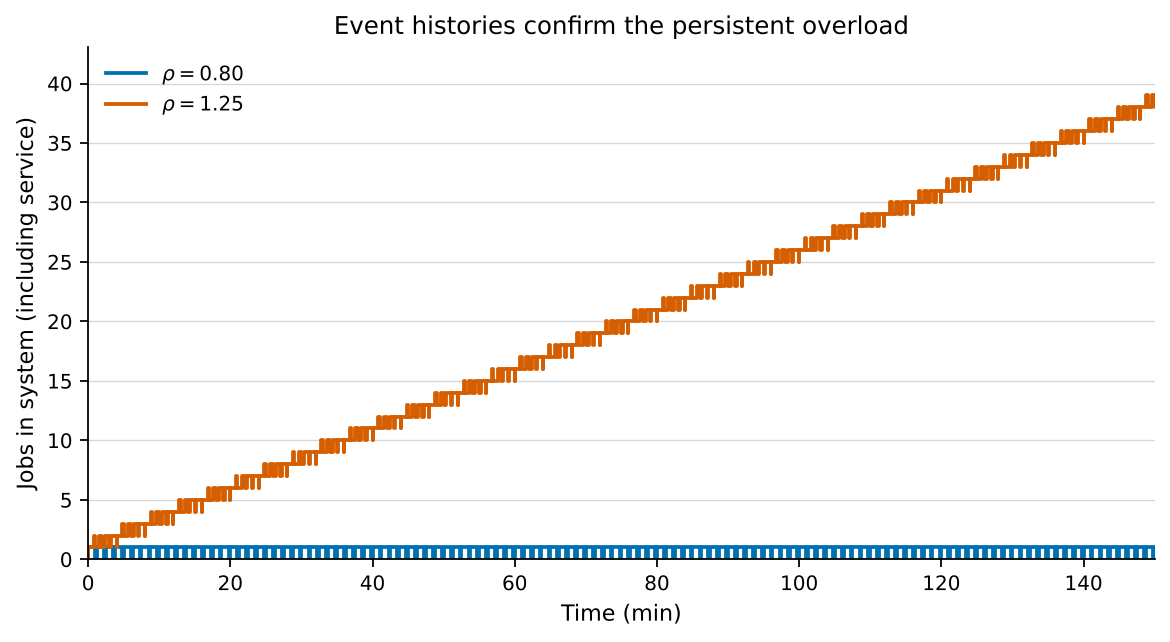

In [15]:
# Create a figure of the number present over a common observation window.
fig, ax = plt.subplots(figsize=(7.2, 3.9), layout="constrained")
# Show the lower-load event history as a post-event step plot.
ax.step(slow_result["times"], slow_result["system"], where="post", color=colors["blue"], linewidth=1.7, label=r"$\rho=0.80$")
# Show the overloaded event history as a contrasting step plot.
ax.step(fast_result["times"], fast_result["system"], where="post", color=colors["red"], linewidth=1.7, label=r"$\rho=1.25$")
# Identify physical elapsed time and its unit.
ax.set_xlabel("Time (min)")
# Distinguish jobs in the system from waiting-only queue length.
ax.set_ylabel("Jobs in system (including service)")
# State the controlled deterministic comparison.
ax.set_title("Event histories confirm the persistent overload")
# Compare only the common interval while both arrival streams are active.
ax.set_xlim(0.0, 150.0)
# Show zero as the natural lower count bound.
ax.set_ylim(bottom=0.0)
# Identify the two offered loads in the figure.
ax.legend(loc="upper left", frameon=False)
# Add light guides for reading the growing number of outstanding jobs.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render both event-driven occupancy histories.
plt.show()

**Figure 3.** Deterministic event histories on the same 0–150 min window. Below load one, each job finishes before the next regular arrival. Above load one, arrivals outpace the one server, so the in-system count grows while arrivals continue. Runs are later drained after their last arrivals; the plotted interval shows ongoing input.

## 4. Irregular arrivals and service times

The regular examples isolate one idea, but a real afternoon has bursts: several students can show up together, then none for a while. Some requests also take longer than others. Even when the desk is fast enough *on average*, those bursts can make a temporary line. A clear line at one moment and a long one ten minutes later need not contradict each other.

For an illustrative stochastic model, draw **independent exponential time gaps** between arrivals and independent exponential service durations. Their respective mean values are $1/\lambda$ and $1/\mu$ minutes. These assumptions define the elementary **$M/M/1$ queue** with one server and unlimited space. The notation is optional; the programming idea is to generate positive random durations and keep a fixed seed for reproducibility. An exponential model is a convenient teaching assumption, not a claim that real lab requests follow that distribution. A fixed seed gives one repeatable realization, not a guarantee of typical behavior.

We stop generating arrivals at a chosen **observation horizon** (the end of the simulated input period), then let accepted jobs finish. This distinguishes the **backlog near the last arrival** from the empty system after complete draining. Two separate random generators let different arrival-rate cases reuse the same underlying sequence of service draws for a more controlled comparison. **Before Figure 5, ask:** Can a load below one still have a busy spell? Can one short run prove that a line will remain forever?

In [16]:
# Define a reproducible schedule of random arrivals and service durations.
def random_schedule(arrival_rate, completion_rate, horizon, seed):
    # Reject rates or a horizon that could not describe this example.
    if arrival_rate <= 0.0 or completion_rate <= 0.0 or horizon <= 0.0:
        # Explain the positive-parameter requirement to the caller.
        raise ValueError("Rates and observation horizon must be positive.")
    # Make one generator dedicated to arrival gaps for this seed.
    arrival_rng = np.random.default_rng(seed)
    # Make a separate generator for service durations from the same seed label.
    service_rng = np.random.default_rng(seed + 10000)
    # Begin before the first random arrival at time zero.
    elapsed = 0.0
    # Prepare a chronological list of arrivals inside the observation interval.
    arrival_list = []
    # Keep generating positive gaps until the next arrival lies beyond the horizon.
    while True:
        # Advance time by an exponential gap with mean 1/lambda minutes.
        elapsed += arrival_rng.exponential(1.0 / arrival_rate)
        # Stop if this attempted arrival would occur beyond the chosen horizon.
        if elapsed > horizon:
            # Leave the loop without adding the out-of-window arrival.
            break
        # Store this in-window arrival for the later event calendar.
        arrival_list.append(elapsed)
    # Draw an independent positive service duration for each attempted arrival.
    services = service_rng.exponential(1.0 / completion_rate, size=len(arrival_list))
    # Return both aligned arrays in physical minutes.
    return np.array(arrival_list), services

In [17]:
# Generate one moderate-load schedule for inspecting random inputs.
sample_arrivals, sample_services = random_schedule(0.85, 1.0, 300.0, 2026)
# Calculate the first 40 gaps, including time from zero to the first arrival.
sample_gaps = np.diff(np.r_[0.0, sample_arrivals[:40]])
# Report how many arrivals occurred and the approximate observed mean gap.
print(f"At λ=0.85 over 300 min: {len(sample_arrivals)} arrivals; first 40 gaps average {np.mean(sample_gaps):.3f} min")
# Check random durations are positive and aligned to their arrivals.
assert len(sample_arrivals) == len(sample_services) and np.all(sample_services > 0.0)

At λ=0.85 over 300 min: 227 arrivals; first 40 gaps average 1.207 min


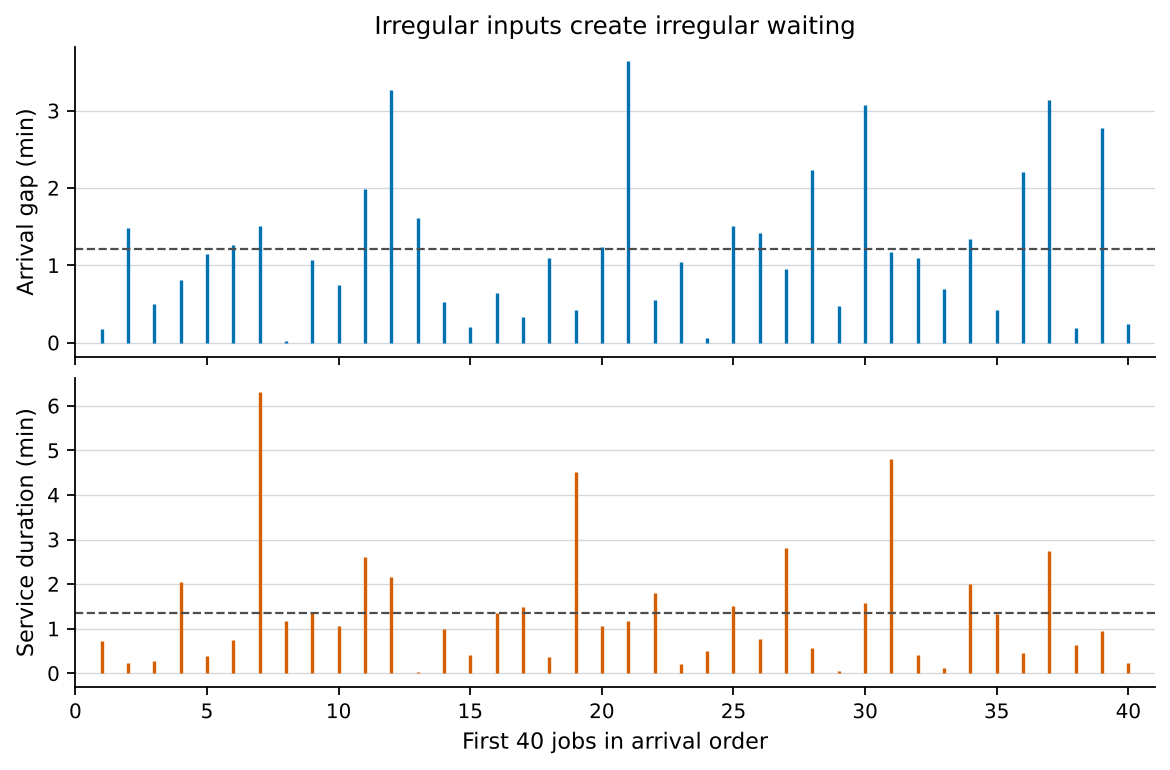

In [18]:
# Make two same-unit panels to compare irregular gaps and service durations.
fig, axes = plt.subplots(2, 1, figsize=(7.2, 4.7), sharex=True, layout="constrained")
# Mark the first 40 random arrival gaps with simple stems.
axes[0].vlines(np.arange(1, 41), 0.0, sample_gaps, color=colors["blue"], linewidth=1.5)
# Mark their measured mean as a visual reference, not a fixed input interval.
axes[0].axhline(np.mean(sample_gaps), color=colors["gray"], linestyle="--", linewidth=1.0)
# Identify the upper set of random time intervals.
axes[0].set_ylabel("Arrival gap (min)")
# Explain that the inputs vary from job to job.
axes[0].set_title("Irregular inputs create irregular waiting")
# Mark the first 40 random service times using a contrasting color.
axes[1].vlines(np.arange(1, 41), 0.0, sample_services[:40], color=colors["red"], linewidth=1.5)
# Mark their observed mean as another descriptive reference.
axes[1].axhline(np.mean(sample_services[:40]), color=colors["gray"], linestyle="--", linewidth=1.0)
# Identify the lower panel's processing duration in minutes.
axes[1].set_ylabel("Service duration (min)")
# Identify the job sequence shared by both input panels.
axes[1].set_xlabel("First 40 jobs in arrival order")
# Restrict the comparison to the actual indices displayed.
axes[1].set_xlim(0.0, 41.0)
# Add faint horizontal guides to each set of measured durations.
axes[0].grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Add corresponding guides to the service-time panel.
axes[1].grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Display the two input schedules without treating them as output queue sizes.
plt.show()

**Figure 4.** First 40 interarrival gaps and service durations from one seeded schedule. Dashed lines mark these particular sample means. Irregular inputs may make the queue temporarily busy even when its long-run offered load is below one.

In [19]:
# Compare four arrival rates against the same nominal one-job-per-minute server.
stochastic_rates = [0.60, 0.85, 1.05, 1.25]
# Use the same 300-minute arrival-generation horizon for all four rates.
stochastic_horizon = 300.0
# Prepare a dictionary of independently simulated event histories.
stochastic_results = {}
# Run a reproducible queue for each specified offered load.
for rate in stochastic_rates:
    # Generate arrivals and aligned services using a common seed label.
    arrivals, services = random_schedule(rate, 1.0, stochastic_horizon, 2026)
    # Simulate the unlimited first-come-first-served system with a heap.
    result = simulate_queue(arrivals, services, method="heap")
    # Check event-by-event conservation before using the result in a figure.
    assert check_accounting(result)
    # Store the full trace under the physical arrival rate.
    stochastic_results[rate] = result
    # Show arrivals, backlog after the last arrival, and mean accepted wait.
    print(f"ρ={rate:.2f}: arrivals={result['attempted']:3d}, backlog after last arrival={result['at_last_arrival']:3d}, mean wait={np.mean(result['wait_times']):.2f} min")

ρ=0.60: arrivals=153, backlog after last arrival=  1, mean wait=1.00 min
ρ=0.85: arrivals=227, backlog after last arrival=  5, mean wait=2.77 min
ρ=1.05: arrivals=283, backlog after last arrival= 17, mean wait=5.90 min
ρ=1.25: arrivals=333, backlog after last arrival= 28, mean wait=18.27 min


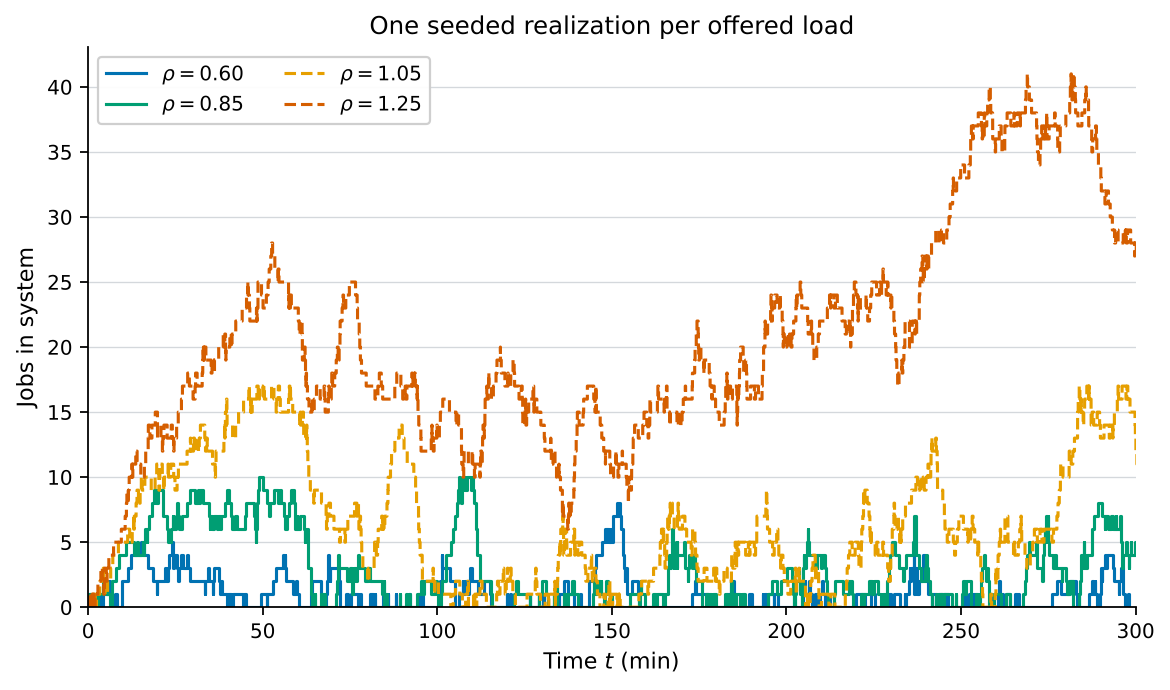

In [20]:
# Create a figure comparing four event histories on one shared time axis.
fig, ax = plt.subplots(figsize=(7.2, 4.2), layout="constrained")
# Assign visibly distinct line colors to increasing offered loads.
trace_colors = [colors["blue"], colors["green"], colors["orange"], colors["red"]]
# Draw each random queue as a step function that changes at events.
for position, rate in enumerate(stochastic_rates):
    # Retrieve the run corresponding to this arrival rate.
    result = stochastic_results[rate]
    # Plot total jobs present, using a dashed pattern above load one.
    ax.step(result["times"], result["system"], where="post", color=trace_colors[position], linestyle="--" if rate > 1.0 else "-", linewidth=1.4, label=fr"$\rho={rate:.2f}$")
# Label physical time in the synthetic factory or service operation.
ax.set_xlabel("Time $t$ (min)")
# Identify the total count, including any job in service.
ax.set_ylabel("Jobs in system")
# State that each curve is one random realization.
ax.set_title("One seeded realization per offered load")
# Restrict the figure to the period in which arrivals were generated.
ax.set_xlim(0.0, stochastic_horizon)
# Show zero as the natural lower bound for a job count.
ax.set_ylim(bottom=0.0)
# Identify the load of each color and line pattern.
ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.94, ncol=2)
# Add light horizontal guides for comparing queue sizes.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render the four stochastic time traces.
plt.show()

**Figure 5.** Four single realizations on the same 0–300 min input period. Curves can fluctuate or have long busy spells; the path of one finite run cannot establish a general stability law. At $\rho>1$, the arrival stream offers more work per unit time than the server can process on average.

### Repeat the experiment instead of trusting one seed

For each load, generate 25 independent 300-minute schedules with distinct seeds. Record the in-system count **just after each run's last arrival**. Report the median and middle half of these 25 values. The endpoint is at the last generated arrival, a little before 300 min; these summaries are finite-horizon teaching statistics, **not** a steady-state estimate or a confidence interval for the threshold.

In [21]:
# Choose six loads on both sides of the theoretical M/M/1 threshold.
load_grid = np.array([0.60, 0.80, 0.95, 1.05, 1.20, 1.40])
# Use 25 independent random seeds at each candidate load.
repeat_count = 25
# Allocate a row per load and a column per independent run.
ending_backlogs = np.empty((len(load_grid), repeat_count))
# Repeat the finite-horizon experiment across all candidate loads.
for row, rate in enumerate(load_grid):
    # Use new random schedules for each repetition at this rate.
    for repeat in range(repeat_count):
        # Generate arrivals and services with a fresh reproducible seed.
        arrivals, services = random_schedule(rate, 1.0, 300.0, 7000 + repeat)
        # Run the unlimited queue and drain after its last arrival.
        result = simulate_queue(arrivals, services, method="heap")
        # Retain the backlog before the later draining phase empties the system.
        ending_backlogs[row, repeat] = result["at_last_arrival"]
# Find the median backlog at each load over its 25 runs.
backlog_medians = np.median(ending_backlogs, axis=1)
# Find the 25th and 75th percentiles of the same finite-run backlogs.
backlog_quartiles = np.quantile(ending_backlogs, [0.25, 0.75], axis=1)
# Show each rate and the two descriptive summaries in jobs.
for row, rate in enumerate(load_grid):
    # Print load, median, and interquartile range without overclaiming precision.
    print(f"ρ={rate:.2f}: median backlog={backlog_medians[row]:.0f} jobs; middle half={backlog_quartiles[0,row]:.0f}–{backlog_quartiles[1,row]:.0f}")

ρ=0.60: median backlog=1 jobs; middle half=1–2
ρ=0.80: median backlog=4 jobs; middle half=2–7
ρ=0.95: median backlog=15 jobs; middle half=7–18
ρ=1.05: median backlog=30 jobs; middle half=21–46
ρ=1.20: median backlog=69 jobs; middle half=55–82
ρ=1.40: median backlog=126 jobs; middle half=112–146


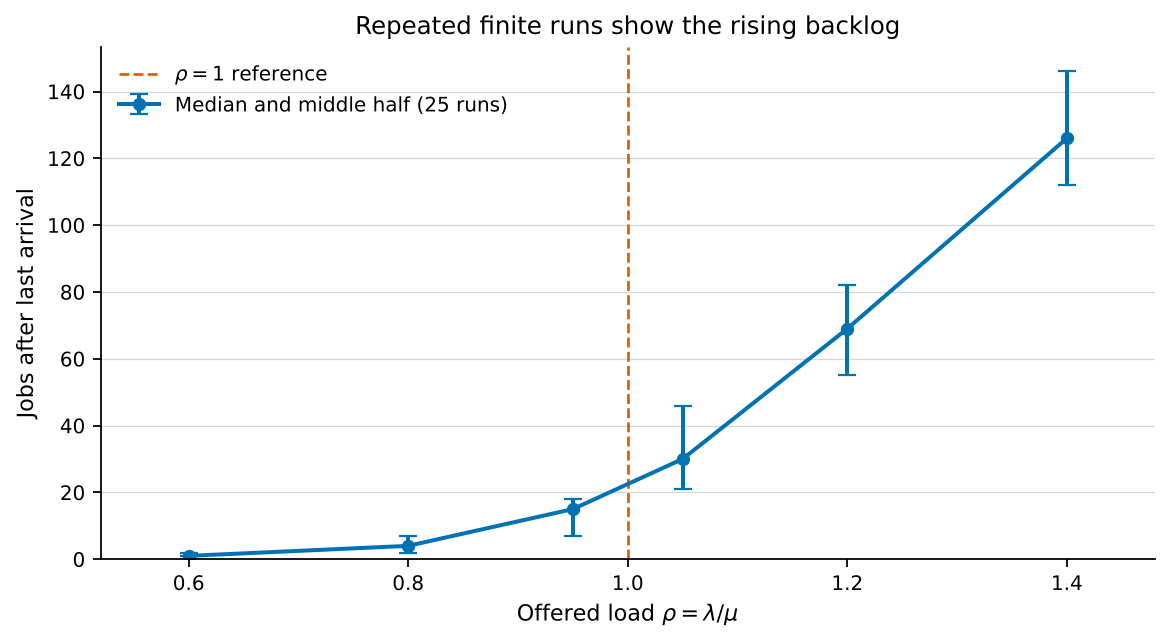

In [22]:
# Create an offered-load figure with median and interquartile bars.
fig, ax = plt.subplots(figsize=(7.2, 3.9), layout="constrained")
# Compute how far the two quartiles lie below and above the median.
quartile_errors = np.vstack((backlog_medians - backlog_quartiles[0], backlog_quartiles[1] - backlog_medians))
# Plot the finite-horizon median and middle-half range at each tested load.
ax.errorbar(load_grid, backlog_medians, yerr=quartile_errors, fmt="o-", color=colors["blue"], ecolor=colors["blue"], linewidth=1.8, capsize=4, markersize=5, label="Median and middle half (25 runs)")
# Mark load one as the reference threshold for the ideal unlimited M/M/1 model.
ax.axvline(1.0, color=colors["red"], linewidth=1.2, linestyle="--", label=r"$\rho=1$ reference")
# Identify the ratio of offered arrival to service rate.
ax.set_xlabel(r"Offered load $\rho=\lambda/\mu$")
# Clarify the finite-run quantity being summarized.
ax.set_ylabel("Jobs after last arrival")
# State that points summarize repeat finite simulations.
ax.set_title("Repeated finite runs show the rising backlog")
# Keep all six simulated loads and the reference threshold visible.
ax.set_xlim(0.52, 1.48)
# Keep job counts nonnegative on the vertical axis.
ax.set_ylim(bottom=0.0)
# Distinguish descriptive summaries from the theoretical threshold line.
ax.legend(loc="upper left", frameon=False)
# Add unobtrusive guides for reading backlog counts.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render the repeated-experiment summary.
plt.show()

**Figure 6.** Median and interquartile backlog after the last arrival of 25 separate runs at each offered load. The dashed line identifies the ideal model's $\rho=1$ boundary. Variability near the boundary explains why a short observation by itself can be misleading.

## 5. Conservation of jobs: arrivals, departures, and a backlog

Counting requests is an engineering check as well as a programming check. If seven requests have arrived, four have left, and none were rejected, **three must still be at the desk or in its line**. A plot showing only the line might hide a request currently being served; counting everyone in the system makes that missing request visible.

When nobody is rejected, **attempted arrivals minus completed departures equals jobs still in the system**, at every event. The vertical gap between cumulative arrivals and departures is thus the outstanding work. With a capacity limit, replace *attempted* by *accepted* arrivals for that identity. The next plot uses the $\rho=1.25$ unlimited stochastic run while arrivals are being generated; its cumulative curves make the accounting visually testable. **Look at Figure 7:** Where the vertical gap widens, what is happening to unfinished requests?

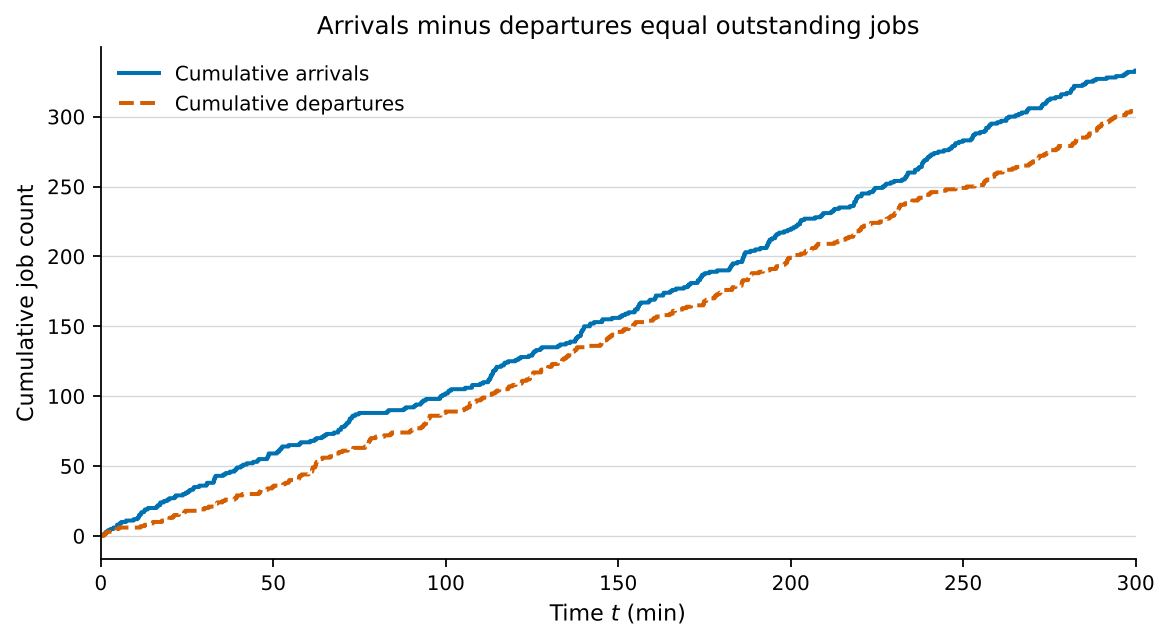

In [23]:
# Select the overloaded stochastic run for a conservation-based view.
count_result = stochastic_results[1.25]
# Verify the cumulative difference equals the recorded system count everywhere.
assert np.array_equal(count_result["attempted_history"] - count_result["completed_history"], count_result["system"])
# Create a single plot of cumulative arrival and departure counts.
fig, ax = plt.subplots(figsize=(7.2, 3.9), layout="constrained")
# Draw all attempted arrivals as a post-event step line.
ax.step(count_result["times"], count_result["attempted_history"], where="post", color=colors["blue"], linewidth=1.8, label="Cumulative arrivals")
# Draw completed departures on the same count scale.
ax.step(count_result["times"], count_result["completed_history"], where="post", color=colors["red"], linewidth=1.8, linestyle="--", label="Cumulative departures")
# Label the physical elapsed time and its unit.
ax.set_xlabel("Time $t$ (min)")
# Identify the cumulative number of processed events of each type.
ax.set_ylabel("Cumulative job count")
# Explain the physical meaning of the gap between the two lines.
ax.set_title("Arrivals minus departures equal outstanding jobs")
# Restrict attention to the common arrival-generation horizon.
ax.set_xlim(0.0, stochastic_horizon)
# Identify the two counter histories.
ax.legend(loc="upper left", frameon=False)
# Add light horizontal guides to aid comparison.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render the cumulative-count identity.
plt.show()

**Figure 7.** Cumulative arrivals and completed departures in one unlimited queue. Their gap at any event is the number of accepted jobs still present. Beyond the last arrival, our simulator keeps processing until that gap reaches zero; the plot focuses on the 300-minute input period.

## 6. What does a queue limit change?

Suppose the desk can admit at most eight requests at once: one with the technician and up to seven waiting. A request that arrives while all eight places are occupied is **rejected** in this model and still counted as an *attempted* arrival. A real lab might offer a booking, send the student elsewhere, or ask them to return; those responses would require new rules and code.

A finite limit prevents the in-system count from exceeding $K$, but it does not make an overloaded server faster. We compare the *same* arrival and service-duration arrays under unlimited space and $K=8$. The rejected fraction is rejected attempts divided by all attempted arrivals. Every admitted job is still drained after arrivals stop. **Before Figure 8, predict:** Could the capped system's occupancy look steady even while unserved demand keeps accumulating? Which panel reveals what happens to that demand?

In [24]:
# Generate one overloaded 500-minute arrival and service schedule.
capacity_arrivals, capacity_services = random_schedule(1.25, 1.0, 500.0, 777)
# Run the schedule without a finite limit for a direct same-input comparison.
unlimited_result = simulate_queue(capacity_arrivals, capacity_services, method="heap")
# Rerun the exact same input with at most eight jobs in the system.
limited_result = simulate_queue(capacity_arrivals, capacity_services, capacity=8, method="heap")
# Check every event's accepted/rejected/departed accounting under the limit.
assert check_accounting(limited_result, capacity=8)
# Compute the share of attempted arrivals turned away at capacity eight.
rejection_fraction = limited_result["rejected"] / limited_result["attempted"]
# Report attempts, rejections, loss share, and the largest actual waiting line.
print(f"K=8: attempted={limited_result['attempted']}, accepted={limited_result['accepted']}, rejected={limited_result['rejected']} ({100*rejection_fraction:.1f}%), max waiting={np.max(limited_result['queue'])}")
# Verify the waiting-only line has at most seven jobs when one is in service.
assert np.max(limited_result["system"]) <= 8 and np.max(limited_result["queue"]) <= 7

K=8: attempted=681, accepted=495, rejected=186 (27.3%), max waiting=7


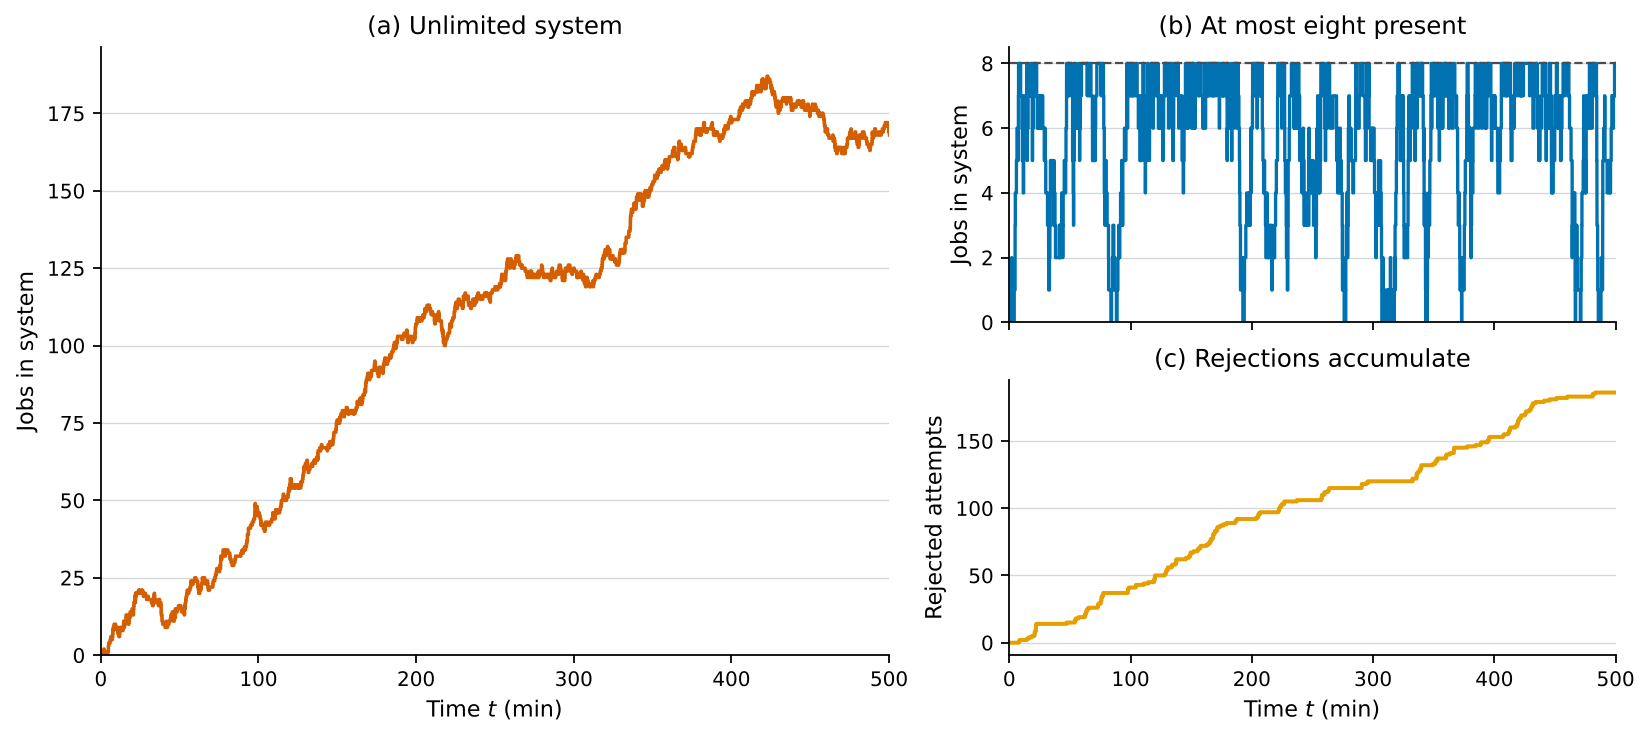

In [25]:
# Create a wider figure with separate readable count scales for three views.
fig = plt.figure(figsize=(10.2, 4.5), layout="constrained")
# Give the unlimited history slightly more room than the diagnostic column.
grid = fig.add_gridspec(2, 2, width_ratios=[1.3, 1.0])
# Use the full left column for the large unlimited-system occupancy.
ax_unlimited = fig.add_subplot(grid[:, 0])
# Use the upper right for the much smaller capacity-eight occupancy.
ax_limited = fig.add_subplot(grid[0, 1])
# Use the lower right for accumulated rejected arrival attempts.
ax_rejected = fig.add_subplot(grid[1, 1], sharex=ax_limited)
# Draw unlimited occupancy with a step at each processed event.
ax_unlimited.step(unlimited_result["times"], unlimited_result["system"], where="post", color=colors["red"], linewidth=1.6)
# Identify the case with no bound on jobs present.
ax_unlimited.set_title("(a) Unlimited system")
# Name the total number present rather than the waiting-only line.
ax_unlimited.set_ylabel("Jobs in system")
# Label the input period in minutes.
ax_unlimited.set_xlabel("Time $t$ (min)")
# Restrict the left view to the interval when jobs arrive.
ax_unlimited.set_xlim(0.0, 500.0)
# Start the unlimited job count at zero.
ax_unlimited.set_ylim(bottom=0.0)
# Draw the capacity-eight total occupancy on its own smaller vertical scale.
ax_limited.step(limited_result["times"], limited_result["system"], where="post", color=colors["blue"], linewidth=1.5)
# Mark the physical limit on this finite-capacity panel.
ax_limited.axhline(8, color=colors["gray"], linestyle="--", linewidth=1.0)
# Explain what the upper-right panel represents.
ax_limited.set_title("(b) At most eight present")
# Distinguish total jobs present from waiting count.
ax_limited.set_ylabel("Jobs in system")
# Keep the full physical limit visible above its zero lower bound.
ax_limited.set_ylim(0.0, 8.5)
# Use simple integer reference ticks for the eight-place system.
ax_limited.set_yticks([0, 2, 4, 6, 8])
# Hide repeated time labels because the lower panel supplies the same scale.
ax_limited.tick_params(labelbottom=False)
# Draw cumulative rejections on their own integer-count scale.
ax_rejected.step(limited_result["times"], limited_result["rejected_history"], where="post", color=colors["orange"], linewidth=1.8)
# Explain the meaning of the lower-right count.
ax_rejected.set_title("(c) Rejections accumulate")
# Label the rejected-attempt count.
ax_rejected.set_ylabel("Rejected attempts")
# Label the shared right-column physical time.
ax_rejected.set_xlabel("Time $t$ (min)")
# Keep the right-hand panels on the 500-minute input interval.
ax_rejected.set_xlim(0.0, 500.0)
# Add light horizontal guides for the unlimited count.
ax_unlimited.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Add matching unobtrusive guides for the finite occupancy.
ax_limited.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Add guides for reading cumulative rejected attempts.
ax_rejected.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Display all three clearly separated physical quantities.
plt.show()

**Figure 8.** The same stochastic arrivals and job durations under unlimited space (a) and $K=8$ (b). Separate vertical scales make both histories legible. The finite system cannot exceed eight present jobs, while rejected attempts accumulate in panel (c). A capped line can look controlled even when requested work exceeds service capacity. If you reported only panel (b) to the lab manager, what important outcome would be missing?

### Averages over time need elapsed-time weights

Each event record is one row, but events do not occur at equal time intervals. A simple average of the rows' queue sizes overweights periods with many events. For the time average over $0\le t\le H$, multiply the number present **between successive events** by the interval length, sum the resulting job-minutes, and divide by $H$. The array of `system` values records the state just after each event; this is why each `system[i]` belongs to the following interval. We clip intervals at the chosen horizon, excluding the later draining phase.

In [26]:
# Define a time average for a state that is constant between events.
def time_average(event_times, after_event_values, horizon):
    # Clip both ends of every inter-event interval to the observation horizon.
    clipped = np.minimum(event_times, horizon)
    # Obtain each nonnegative interval length, including zero-length tied events.
    durations = np.diff(clipped)
    # Weight each interval by the value present after its preceding event.
    total_job_minutes = np.sum(durations * after_event_values[:-1])
    # Divide accumulated job-minutes by physical time to obtain average jobs.
    return total_job_minutes / horizon
# Compute physically time-weighted occupancy over the 500-minute input period.
weighted_system = time_average(limited_result["times"], limited_result["system"], 500.0)
# Compute an unweighted event-record average for contrast only.
event_row_average = np.mean(limited_result["system"])
# Print both numbers and identify the correctly time-weighted one.
print(f"K=8 average jobs in system: time-weighted={weighted_system:.3f}; unweighted event-row average={event_row_average:.3f}")
# Check that the correct finite-capacity time average is between zero and eight.
assert 0.0 <= weighted_system <= 8.0

K=8 average jobs in system: time-weighted=5.732; unweighted event-row average=5.848


## 7. Correctness first, then efficiency

Because sorting and heaps are two calendar implementations of the **same** event rules, they should give identical counts, event times, labels, occupancies, and waiting times for one fixed input schedule and capacity. We compare their complete traces on a small random schedule before timing them. Run times depend on the computer, Python version, job count, and background activity; the benchmark illustrates a trend rather than claiming a universal speedup.

In [27]:
# Make a modest seeded schedule with enough events to check both methods.
comparison_arrivals, comparison_services = random_schedule(1.10, 1.0, 45.0, 992)
# Simulate with the teaching implementation that sorts the pending list.
sorted_result = simulate_queue(comparison_arrivals, comparison_services, capacity=6, method="sorted")
# Simulate the identical jobs and capacity with a priority queue.
heap_result = simulate_queue(comparison_arrivals, comparison_services, capacity=6, method="heap")
# Check each numerical history rather than only final summary counts.
for key in ["times", "system", "queue", "attempted_history", "accepted_history", "completed_history", "rejected_history", "wait_times"]:
    # Raise an assertion at the first mismatch in a named output array.
    assert np.array_equal(sorted_result[key], heap_result[key]), key
# Check textual event labels as well as numerical histories.
assert sorted_result["labels"] == heap_result["labels"]
# Check that both calendar modes satisfy the finite-capacity invariants.
assert check_accounting(sorted_result, capacity=6) and check_accounting(heap_result, capacity=6)
# Report the number of jobs used in the complete-trace equivalence check.
print(f"Sorted list and heap agree at every event for {len(comparison_arrivals)} attempted jobs.")

Sorted list and heap agree at every event for 46 attempted jobs.


 100 jobs: repeated sorting 0.0015 s; heap 0.0004 s
 400 jobs: repeated sorting 0.0200 s; heap 0.0020 s


1000 jobs: repeated sorting 0.1337 s; heap 0.0052 s


2000 jobs: repeated sorting 0.4422 s; heap 0.0110 s


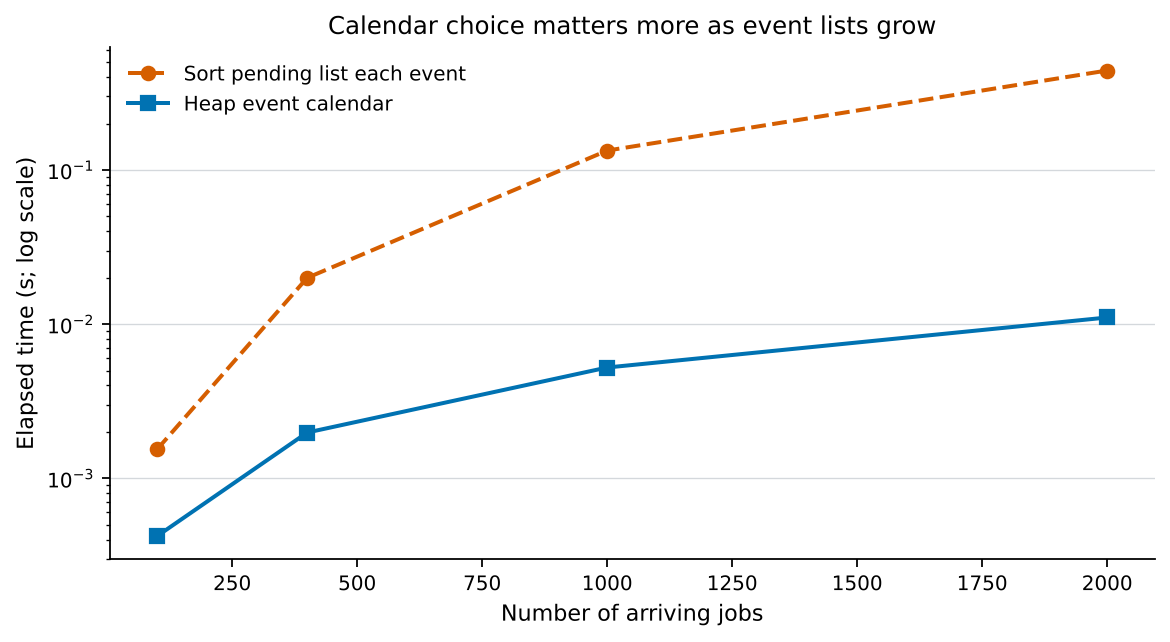

In [28]:
# Compare several deterministic input sizes on the same computer session.
benchmark_sizes = [100, 400, 1000, 2000]
# Prepare to collect a median elapsed time for the sorted-list calendar.
sorted_seconds = []
# Prepare corresponding median times for the heap calendar.
heap_seconds = []
# Repeat each size to reduce the effect of one unusual timing sample.
for count in benchmark_sizes:
    # Make an overloaded but identical regular schedule for both implementations.
    test_arrivals = np.arange(count) * 0.80
    # Assign each job the same one-minute processing duration.
    test_services = np.ones(count)
    # Collect two sorted-list timings for the current input size.
    sorted_trials = []
    # Collect two heap timings for the same input.
    heap_trials = []
    # Repeat the comparison twice at each size, in the same order.
    for repeat in range(2):
        # Record wall-clock time before the sorted-list run.
        start_sorted = clock.perf_counter()
        # Process this input by repeatedly sorting the entire pending list.
        simulate_queue(test_arrivals, test_services, method="sorted")
        # Save elapsed wall-clock time in seconds for this repetition.
        sorted_trials.append(clock.perf_counter() - start_sorted)
        # Record wall-clock time before the heap run.
        start_heap = clock.perf_counter()
        # Process exactly the same input with the heap calendar.
        simulate_queue(test_arrivals, test_services, method="heap")
        # Save the heap elapsed time for this repetition.
        heap_trials.append(clock.perf_counter() - start_heap)
    # Store the middle elapsed time of the two sorted-list repeats.
    sorted_seconds.append(np.median(sorted_trials))
    # Store the corresponding median heap elapsed time.
    heap_seconds.append(np.median(heap_trials))
    # Report both observed timings without presenting them as universal constants.
    print(f"{count:4d} jobs: repeated sorting {sorted_seconds[-1]:.4f} s; heap {heap_seconds[-1]:.4f} s")
# Make one figure of the measured execution times against input size.
fig, ax = plt.subplots(figsize=(7.2, 3.9), layout="constrained")
# Plot the pedagogical repeatedly sorted calendar timings.
ax.plot(benchmark_sizes, sorted_seconds, "o--", color=colors["red"], linewidth=1.8, label="Sort pending list each event")
# Plot the corresponding priority-queue timings.
ax.plot(benchmark_sizes, heap_seconds, "s-", color=colors["blue"], linewidth=1.8, label="Heap event calendar")
# Name the count of attempted jobs used to generate each benchmark run.
ax.set_xlabel("Number of arriving jobs")
# Give measured time and unit while explaining the logarithmic spacing.
ax.set_ylabel("Elapsed time (s; log scale)")
# Explain that the implementation of the calendar is the changed variable.
ax.set_title("Calendar choice matters more as event lists grow")
# Identify the two ways of selecting the next event.
ax.legend(loc="upper left", frameon=False)
# Use a log scale so both fast and slow implementations remain visible.
ax.set_yscale("log")
# Add faint horizontal guides for reading timing differences.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render the local, machine-dependent efficiency illustration.
plt.show()

**Figure 9.** Two repetitions per input size, summarized by their median elapsed time on this machine. The vertical axis is logarithmic, so equal vertical gaps indicate equal ratios of time. The same event rules produce the same answers. Sorting the entire pending list for every event becomes relatively expensive as the list grows; a heap efficiently maintains the next event. Small timing differences can vary across runs.

## 8. Increasing service capacity versus enlarging the buffer

The lab manager has two very different ideas: make more room for waiting requests, or complete each request sooner. More room can postpone or reduce rejection during a finite rush, but it cannot increase what one server completes per minute. Faster service changes the offered load. In practice that might mean a better tool or a simpler check; here it is a controlled mathematical change, not a costed staffing proposal.

We keep the same arrival times and the same relative job-duration pattern, but divide every service duration by 1.5. This represents a server that is 1.5 times faster on each job, changing nominal $\mu$ from 1.0 to 1.5 jobs/min and the nominal load from 1.25 to about 0.83. The shorter service times may still leave occasional waiting because arrivals and durations vary. **Explain Figure 10 in one sentence:** Which intervention changes the rate balance, and which only changes how much work can be stored?

Backlog after last arrival: original server=172; 1.5× faster server=4 jobs


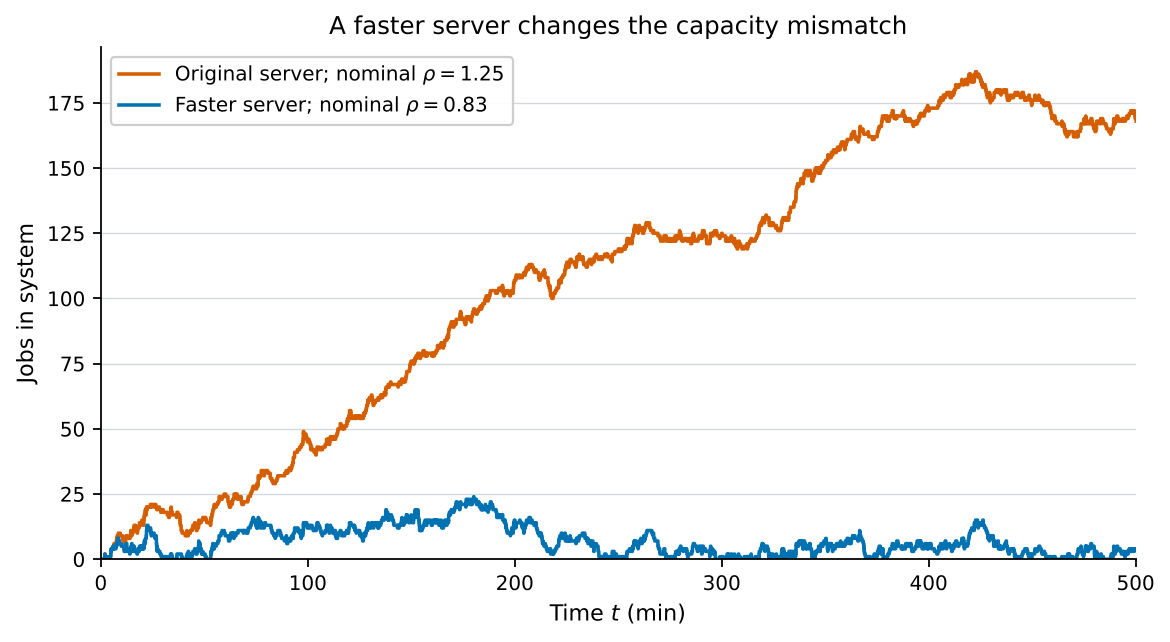

In [29]:
# Keep the overloaded 500-minute arrival schedule exactly as before.
faster_arrivals = capacity_arrivals.copy()
# Shorten each job's service duration by the same factor of 1.5.
faster_services = capacity_services / 1.5
# Simulate the faster server with unlimited waiting space.
faster_result = simulate_queue(faster_arrivals, faster_services, method="heap")
# Confirm the inputs represent exactly the same attempted arrivals.
assert faster_result["attempted"] == unlimited_result["attempted"]
# Check all arrival/departure identities for the faster server.
assert check_accounting(faster_result)
# Compare the backlogs just after the final attempted arrival in each run.
print(f"Backlog after last arrival: original server={unlimited_result['at_last_arrival']}; 1.5× faster server={faster_result['at_last_arrival']} jobs")
# Make a direct same-input comparison of occupancy histories.
fig, ax = plt.subplots(figsize=(7.2, 3.9), layout="constrained")
# Draw the original server's unlimited queue over the input period.
ax.step(unlimited_result["times"], unlimited_result["system"], where="post", color=colors["red"], linewidth=1.6, label=r"Original server; nominal $\rho=1.25$")
# Draw the faster server's corresponding system occupancy.
ax.step(faster_result["times"], faster_result["system"], where="post", color=colors["blue"], linewidth=1.6, label=r"Faster server; nominal $\rho=0.83$")
# Label physical elapsed time in minutes.
ax.set_xlabel("Time $t$ (min)")
# Specify that the count includes any job being served.
ax.set_ylabel("Jobs in system")
# State the operational change illustrated by the two curves.
ax.set_title("A faster server changes the capacity mismatch")
# Compare only while the shared arrival stream is present.
ax.set_xlim(0.0, 500.0)
# Keep the count axis grounded at zero jobs.
ax.set_ylim(bottom=0.0)
# Label the two physical service-rate cases.
ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.95)
# Add light horizontal guides for reading occupancy.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render the controlled service-speed sensitivity comparison.
plt.show()

**Figure 10.** The same arriving jobs and relative service-duration variation, with service times shortened by 1.5 in one case. Increasing service capacity changes the offered load; a bigger buffer alone can only store or reject excess work during overload.

## 9. Guided exercise: choose a finite waiting area

You are advising the campus lab desk for one illustrative 300-minute shift. The input has nominal $\lambda=0.90$ and the technician has nominal $\mu=1.0$ jobs/min. The manager asks for the smallest total capacity among $K=2,4,8,16,32$ whose rejected fraction does not exceed 5% **in this one synthetic shift**. Remember that one of those places is occupied by the request in service.

Run all capacities on the *same* arrival and service arrays, compute rejected/attempted for each, and report the first tested capacity meeting the target. Then write a two-sentence recommendation: give the chosen $K$ and the observed rejected fraction; explain why one simulated shift is not a service-level guarantee. A real design should examine many shifts, uncertain arrival patterns, the consequences of rejection, and the cost of capacity.

In [30]:
# Generate a reproducible moderate-load shift for the exercise.
exercise_arrivals, exercise_services = random_schedule(0.90, 1.0, 300.0, 991)
# Define the allowed physical capacities, including the one service position.
capacity_options = [2, 4, 8, 16, 32]
# Set a desired maximum rejected fraction for this one generated shift.
target_loss = 0.05
# Start without assuming that any tested capacity will satisfy the target.
chosen_capacity = None
# Try each offered system capacity using the identical job inputs.
for option in capacity_options:
    # Simulate the finite system and drain all accepted work afterward.
    trial = simulate_queue(exercise_arrivals, exercise_services, capacity=option, method="heap")
    # Verify event-by-event accounting and the total-system limit.
    assert check_accounting(trial, capacity=option)
    # Divide rejections by attempted arrivals to obtain the shift's loss fraction.
    loss = trial["rejected"] / trial["attempted"]
    # Display option, observed percentage rejected, and largest waiting count.
    print(f"K={option:2d}: rejected {trial['rejected']:2d}/{trial['attempted']} = {100*loss:5.2f}%; max waiting={np.max(trial['queue'])}")
    # Test the first capacity whose observed loss meets the requested threshold.
    if chosen_capacity is None and loss <= target_loss:
        # Keep the first acceptable option because options are in ascending order.
        chosen_capacity = option
# Report the outcome without pretending that one shift determines future risk.
print(f"Smallest tested K meeting 5% loss in this shift: {chosen_capacity}")
# Check that this chosen input has at least one admissible tested capacity.
assert chosen_capacity is not None

K= 2: rejected 75/266 = 28.20%; max waiting=1
K= 4: rejected 41/266 = 15.41%; max waiting=3
K= 8: rejected 14/266 =  5.26%; max waiting=7
K=16: rejected  0/266 =  0.00%; max waiting=15
K=32: rejected  0/266 =  0.00%; max waiting=15
Smallest tested K meeting 5% loss in this shift: 16


## What to take away

1. **Events and classes:** named `Job` and `Event` objects make arrival, departure, tie priority, and processing duration explicit. A sorted event list is easy to understand; a heap handles larger lists more efficiently.
2. **Accounting:** at every event, attempts = accepted + rejected, while accepted = completed + jobs currently in the system. Queue length counts waiting only; system capacity includes the job in service.
3. **Persistence:** regular arrivals that continually outpace a server build a growing backlog with unlimited space. The ideal stochastic $M/M/1$ model has a stationary regime only for $\rho<1$; a finite path can still have long queues below that threshold.
4. **Engineering choice:** a limited buffer bounds in-system occupancy but can reject jobs. Faster service changes the load. A benchmark or a single random run should be interpreted within its observation horizon and assumptions.

**Transfer the idea:** A request could instead be a sample awaiting a test instrument, a part awaiting inspection, or a task awaiting a computer. For one of these examples, identify the job, server, arrival, departure, and possible rejection. Then explain which rules would change in the model. The programming pattern—events, a waiting collection, checks, and comparison of alternatives—can travel with you to many engineering fields.

**Further exercises:** change the simultaneous-event tie rule and predict how the tiny $K=2$ example changes; use two different random seeds at the same offered load; use `capacity=1` to model a server without a waiting place; repeat the final capacity exercise for many shifts and report the distribution of rejected fractions. For an advanced project, compare a second server or non-exponential service times; this notebook's $M/M/1$ threshold and formulas would then need to be reconsidered carefully.

**Assumptions and limits:** one server, first-come-first-served, no job abandonment, positive service times, and no preemption. Arrival and service distributions are explicitly assumed in the stochastic section. We schedule a finite list of arrivals and drain accepted jobs after the input stops; this makes the final system count zero even after an overloaded period. A finite capacity is a limit on jobs **present**, not on all attempted arrivals.

**Optional primary-source reading:** [MIT OpenCourseWare, *Queueing Systems*](https://ocw.mit.edu/courses/1-203j-logistical-and-transportation-planning-methods-fall-2006/resources/lec5/) discusses queue terminology, state balance, and dynamic behavior; [MIT OpenCourseWare, *Data Communication Networks* lecture slides](https://www.ocw.mit.edu/courses/6-263j-data-communication-networks-fall-2002/7f088bd3a28400155989d6bc5e078adc_Lectures10_11.pdf) state the $M/M/1$ condition $\lambda<\mu$ for finite mean delay; [MIT OpenCourseWare, *Queueing Systems II*](https://ocw.mit.edu/courses/1-203j-logistical-and-transportation-planning-methods-fall-2006/resources/lec6/) discusses finite system capacity. These readings go beyond the programming essentials of this notebook.